In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy as sp
import timeit
from IPython import display
import copy
import math
import pygame
import sys

pygame 2.6.1 (SDL 2.28.4, Python 3.13.0)
Hello from the pygame community. https://www.pygame.org/contribute.html


## Exercise 0: Import Statements

To start, run the first Python cell of this sheet (the one on top!) to import all dependencies. 

If e.g., the import of `scipy` fails, and the cells are interpreted by the `/usr/bin/python3` kernel, the following command installs the missing package on a Linux system

```sh
/usr/bin/python3 -m pip install scipy -U --user --force-reinstall
```

If this cell succeeds, your system is ready to solve all remaining sheets!

## Exercise 1: Defining Functions

We will usually ask for implementations in the cells of a Jupyter notebook, where the structure is already prepared and code to be completed is usually indicated by the
-  ```pass``` Statement
-  or the following placeholder

```python
    '''your code here'''
    '''***        ***'''
```
  
-   E.g., please implement the function

$$f(x) = \cos(x) \exp(x)$$

in the cell below and print the evaluation of the function at $x=-2\pi$ and $x=2\pi$.

Finally, run the cell below after implementation and check if the result is correct ($\sim 0.0019$ for $x=-2\pi$ and $\sim 535.5$ for $x=2\pi$).

In [14]:
def f(x):
    x = np.cos(x)*np.exp(x)
    return x

print(f(x = -2*np.pi))
print(f(x = 2*np.pi))

0.0018674427317079893
535.4916555247646


## Exercise 2: Plotting Data

Every Python cell of a Jupyter Notebook is a script which can be re-evaluated later (if it has been executed before!). It can contain multiple functions and other numerical computations all in one notebook or even in one cell of a notebook. The ```matplotlib.pyplot``` module can be used for plotting.

- a) In the cell below write commands which plot the graph of the function $f$ in
the half-open interval $[−2\pi,2\pi)$. Hint: python’s numpy module has as a special variable for $\pi$:
np.pi

- b) Display the resulting plot directly in the notebook and compare if it is correct. I.e., it should look like 

![plot](./ref_plot.png)

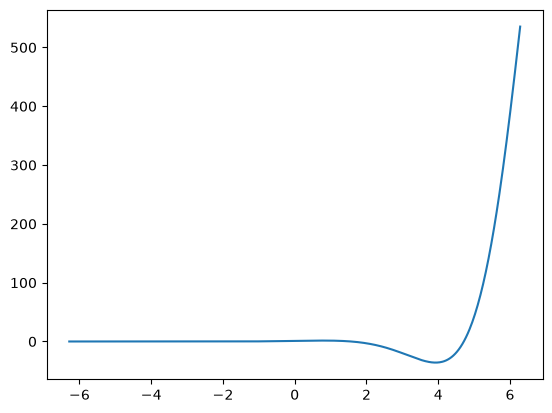

<Figure size 640x480 with 0 Axes>

In [42]:
# create interval from -2 π to 2 π
def f(x):
    return np.cos(x) * np.exp(x)

x = np.linspace(-2 * np.pi, 2 * np.pi, 500)
# plot f(x)
plt.plot(x,f(x))
# show plot
plt.show()
# clear plot again
plt.clf()

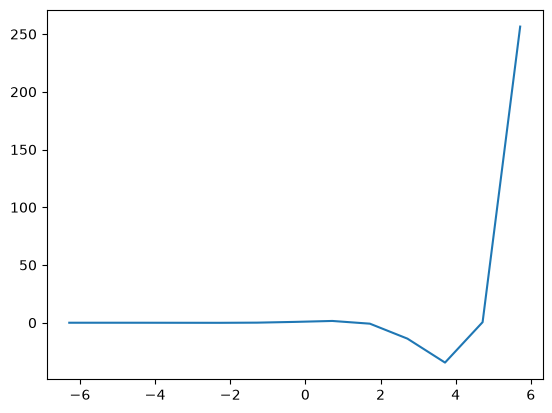

<Figure size 640x480 with 0 Axes>

In [ ]:
# create interval from -2 π to 2 π
def f(x):
    return np.cos(x) * np.exp(x)

x = np.arange(-2 * np.pi, 2 * np.pi)
# plot f(x)
plt.plot(x,f(x))
# show plot
plt.show()
# clear plot again
plt.clf()

 - (c) Check if dynamic plotting works on your machine, by running the following cell. You should see one plot, which is updated over time.

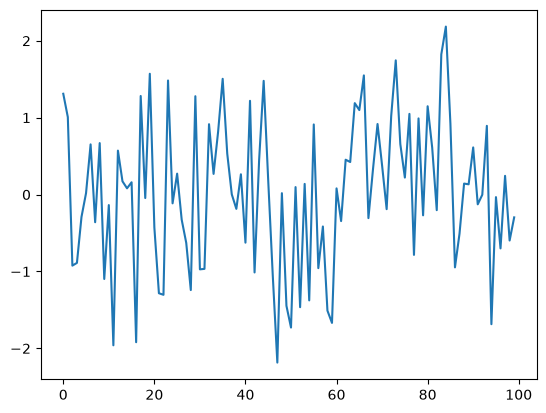

In [46]:
for i in range(10):
    plt.plot(np.random.randn(100))
    plt.show()
    if i != 9:
        display.clear_output(wait=True)
    plt.pause(.5)

## Exercise 3: Generating Random Numbers

Random numbers are important in probabilistic robotics so it is preferable to know what kind of random variables are provided by Python and how to use them. Hint: use numpy

- a) Create a vector with 100000 random variables which are normally distributed with a mean of 5.0 and a standard deviation of 2.0.

In [85]:
rand_norm = np.random.normal(loc = 5.0, scale = 2.0, size = 100000)
print(rand_norm)

[3.36430268 9.98824677 5.72393323 ... 6.20540276 5.43345672 7.3942326 ]


- b) Create a vector with 100000 uniformly distributed random variables between 0 and 10.

In [120]:
rand_uni = np.random.uniform(low = 0, high = 10, size = 100000)
print(rand_uni)

[2.35465367 4.31231857 9.23380163 ... 9.11682364 3.72472685 2.17706164]


Finally, compute the mean and standard deviation of the two vectors with random variables.

In [124]:
def compute_and_print_mean_and_std(x):
    # compute mean and std
    mean = np.mean(x) 
    std = np.std(x)

    print(f"Mean: {mean}, Standard deviation: {std}")

    # print mean and std
    


print("++ rand_norm ++")
compute_and_print_mean_and_std(rand_norm)

print("++ rand_uni ++")
compute_and_print_mean_and_std(rand_uni)

++ rand_norm ++
Mean: 5.003492267078943, Standard deviation: 1.9984397838100327
++ rand_uni ++
Mean: 4.997464269937587, Standard deviation: 2.889336855072513


Are the results what you would expect?

**Answer: Da für rand_norm vorgegeben wurde, wie der Mean und die Standard Deviation aussehen sollen, war zu erwarten, dass diese bei einer so großen Versuchsanzahl auch nahezu bei den exakten Werten landen sollten. Bei rand_uni kommt man bei einer Gleichverteilung der Zahlen auch auf ca 5 /1+2+3+4+5+6+7+8+9+10 = 60,  60 durch 11 = 5,45 /. Zur Standardabweichung wüsst ich nur, dass 3 Standardabweichungen ca 99,7% aller Messwerte umfassen.**

- d) Plot histograms of the random variables you generated. The hist command can be used to plot histograms. Take a look at help(matplotlib.pyplot.hist) for more
information about how to use it.

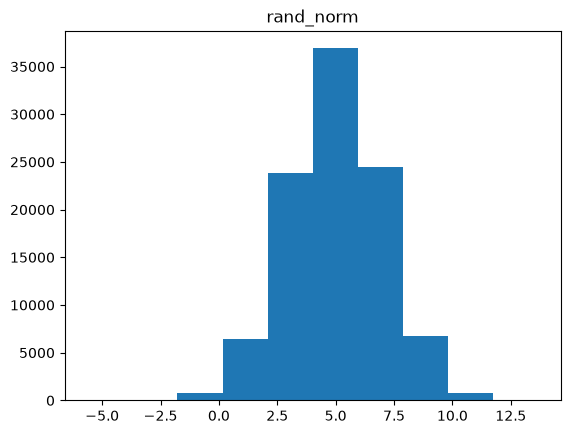

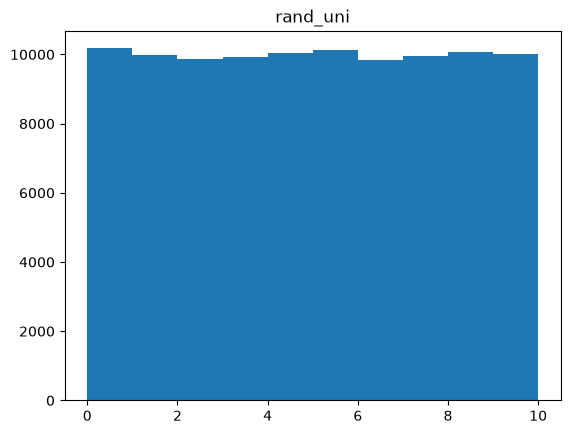

<Figure size 640x480 with 0 Axes>

In [127]:
def plot_histogram(x, name):
    # plot histogram
    plt.hist(x)
    # set title
    plt.title(name)
    # show plot 
    plt.show()
    # clear plot again
    plt.clf()

plot_histogram(rand_norm, "rand_norm")
plot_histogram(rand_uni, "rand_uni")

- e) Modify your script such that the generated distributions are exactly the same each time
you call it.

In [133]:
np.random.seed(1)
# evaluate repeatedly an check if moments are stable
for i in range(5):
    rand_norm = np.random.normal(loc = 5.0, scale = 2.0, size = 100000)
    rand_uni  = np.random.uniform(low = 0, high = 10, size = 100000)

    print("++ rand_norm ++")
    compute_and_print_mean_and_std(rand_norm)

    print("++ rand_uni ++")
    compute_and_print_mean_and_std(rand_uni)


print("---------- fixed random numbers ----------")

np.random.seed(1)
# evaluate repeatedly an check if moments are stable
for i in range(5):
    rand_norm = np.random.normal(loc = 5.0, scale = 2.0, size = 100000)
    rand_uni  = np.random.uniform(low = 0, high = 10, size = 100000)

    print("++ rand_norm ++")
    compute_and_print_mean_and_std(rand_norm)

    print("++ rand_uni ++")
    compute_and_print_mean_and_std(rand_uni)


++ rand_norm ++
Mean: 5.010506056979365, Standard deviation: 1.9966585470834726
++ rand_uni ++
Mean: 4.989286884421565, Standard deviation: 2.8836541332144052
++ rand_norm ++
Mean: 4.998309185929916, Standard deviation: 2.003453997642875
++ rand_uni ++
Mean: 5.002784206437085, Standard deviation: 2.885016326825125
++ rand_norm ++
Mean: 4.995425667206431, Standard deviation: 2.001181045403238
++ rand_uni ++
Mean: 5.001583944602373, Standard deviation: 2.890773179489818
++ rand_norm ++
Mean: 5.008451678263933, Standard deviation: 1.9993446769958008
++ rand_uni ++
Mean: 4.99327729899224, Standard deviation: 2.8846380484825955
++ rand_norm ++
Mean: 5.006151550978209, Standard deviation: 2.0035845460996478
++ rand_uni ++
Mean: 4.981768540353361, Standard deviation: 2.888372324102417
---------- fixed random numbers ----------
++ rand_norm ++
Mean: 5.010506056979365, Standard deviation: 1.9966585470834726
++ rand_uni ++
Mean: 4.989286884421565, Standard deviation: 2.8836541332144052
++ rand_n

# 4. Run PygGame

If you see a bouncing ball, you are all set to build your robot! 

In [134]:
pygame.init()
screen = pygame.display.set_mode((640, 480))
pygame.display.set_caption("pygame demo")
clock = pygame.time.Clock()

x, y, dx, dy, r = 320, 240, 4, 3, 20

running = True
while running:
    for event in pygame.event.get():
        if event.type == pygame.QUIT:
            running = False

    x, y = x + dx, y + dy
    if x - r < 0 or x + r > 640:
        dx = -dx
    if y - r < 0 or y + r > 480:
        dy = -dy

    screen.fill((30, 30, 40))
    pygame.draw.circle(screen, (255, 120, 80), (x, y), r)
    pygame.display.flip()
    clock.tick(60)

pygame.quit()